## ⚙️ Setup: libraries, helper function and our sample image


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.titlesize": 11})
np.random.seed(0)                       # same random numbers every run

def show(images, titles, cols=3, size=4, suptitle=None):
    """Show images side by side. Color images are BGR (OpenCV), gray images are 2D."""
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size * 0.8 + 0.7))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, img, title in zip(axes, images, titles):
        if img.ndim == 2:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])        # thin frame so white images stay visible
        for spine in ax.spines.values():
            spine.set_color("#999999")
    if suptitle:
        fig.suptitle(suptitle, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

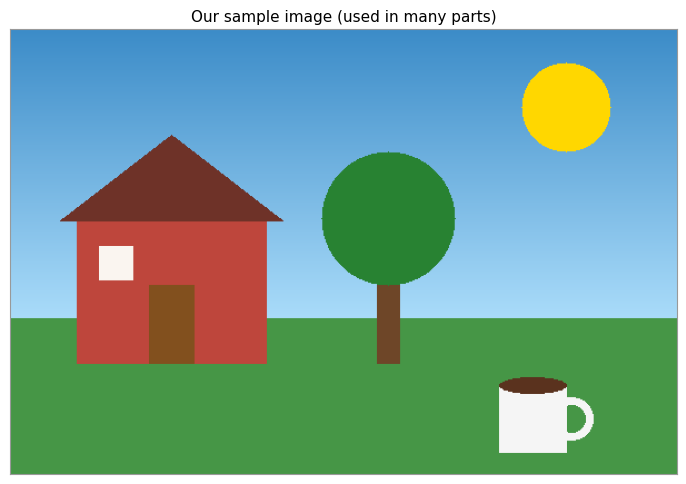

In [ ]:
def make_scene():
    """Draw a simple picture. Also returns a label map and boxes (used later in Part 8)."""
    H, W = 400, 600
    img = np.zeros((H, W, 3), np.uint8)
    labels = np.zeros((H, W), np.uint8)
    for y in range(260):                                   # sky gradient
        t = y / 260
        img[y, :] = (200 + 50 * t, 140 + 80 * t, 60 + 110 * t)
    img[260:] = (70, 150, 70)                              # grass
    labels[260:] = 1

    def paint(draw, color, label):                         # draw on picture AND label map
        draw(img, color); draw(labels, label)

    paint(lambda im, c: cv2.circle(im, (500, 70), 40, c, -1), (0, 215, 255), 5)            # sun
    paint(lambda im, c: cv2.rectangle(im, (60, 170), (230, 300), c, -1), (60, 70, 190), 2)  # house
    paint(lambda im, c: cv2.fillPoly(im, [np.array([[45, 172], [145, 95], [245, 172]], np.int32)], c), (40, 50, 110), 2)  # roof
    paint(lambda im, c: cv2.rectangle(im, (125, 230), (165, 300), c, -1), (30, 80, 130), 2)   # door
    paint(lambda im, c: cv2.rectangle(im, (80, 195), (110, 225), c, -1), (240, 245, 250), 2)  # window
    paint(lambda im, c: cv2.rectangle(im, (330, 210), (350, 300), c, -1), (40, 70, 110), 3)    # trunk
    paint(lambda im, c: cv2.circle(im, (340, 170), 60, c, -1), (50, 130, 40), 3)               # leaves
    paint(lambda im, c: cv2.rectangle(im, (440, 320), (500, 380), c, -1), (245, 245, 245), 4)  # cup
    paint(lambda im, c: cv2.circle(im, (505, 350), 16, c, 6), (245, 245, 245), 4)              # handle
    paint(lambda im, c: cv2.ellipse(im, (470, 320), (30, 7), 0, 0, 360, c, -1), (30, 50, 90), 4)  # coffee
    boxes = {"house": (45, 95, 245, 300), "tree": (280, 110, 400, 300), "cup": (440, 313, 524, 380)}
    return img, labels, boxes

scene, scene_labels, scene_boxes = make_scene()
show([scene], ["Our sample image (used in many parts)"], cols=1, size=7)

# Part 1: Introduction to image processing

**Image processing** = changing or measuring an image with code (make it brighter, remove noise, find edges)


**Computer vision** = making a computer *understand* what is in an image (for example "this is a house")

Image processing is often one step *inside* a computer vision system

**How does a computer see an image?** As a grid of numbers
- A **pixel** is one small square of the picture
- Image **dimensions** = height × width in pixels
- A **color channel** is one layer of color. Color images have 3 (Blue, Green, Red in OpenCV). Gray images have 1
- Each number runs from **0 (black)** to **255 (white)**

Color image shape: (400, 600, 3)  -> (height, width, channels)
Gray image shape:  (400, 600)  -> (height, width)


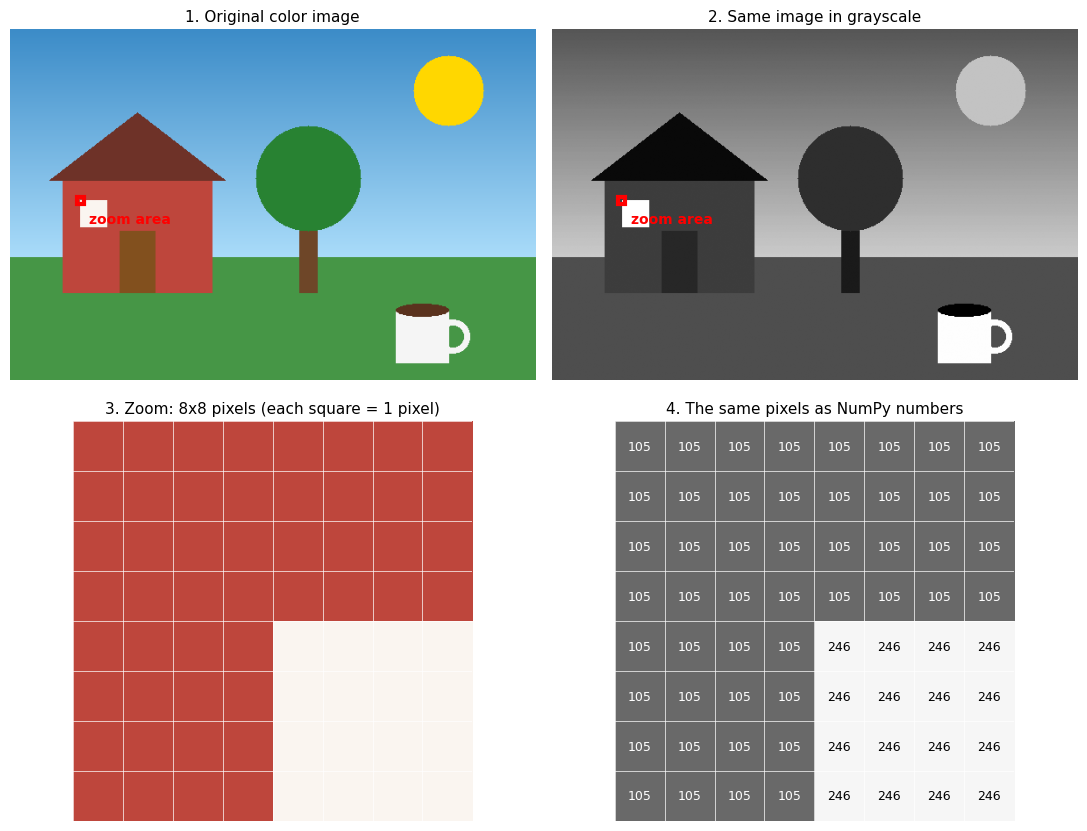

In [ ]:
gray = cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY)
print("Color image shape:", scene.shape, " -> (height, width, channels)")
print("Gray image shape: ", gray.shape,  " -> (height, width)")

y, x = 191, 76                                   # top-left corner of a tiny 8x8 crop near the window
rgb = cv2.cvtColor(scene, cv2.COLOR_BGR2RGB)
tiny_gray, tiny_rgb = gray[y:y+8, x:x+8], rgb[y:y+8, x:x+8]

fig, ax = plt.subplots(2, 2, figsize=(11, 8.5))
ax[0, 0].imshow(rgb);                ax[0, 0].set_title("1. Original color image")
ax[0, 1].imshow(gray, cmap="gray");  ax[0, 1].set_title("2. Same image in grayscale")
for a in ax[0]:
    a.add_patch(plt.Rectangle((x - 0.5, y - 0.5), 8, 8, fill=False, ec="red", lw=3))
    a.text(x + 14, y + 30, "zoom area", color="red", fontsize=10, weight="bold")
    a.axis("off")

ax[1, 0].imshow(tiny_rgb, interpolation="nearest"); ax[1, 0].set_title("3. Zoom: 8x8 pixels (each square = 1 pixel)")
ax[1, 1].imshow(tiny_gray, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
ax[1, 1].set_title("4. The same pixels as NumPy numbers")
for r in range(8):
    for c in range(8):
        v = tiny_gray[r, c]
        ax[1, 1].text(c, r, str(v), ha="center", va="center", fontsize=9, color="white" if v < 128 else "black")
for a in ax[1]:
    for i in range(9):
        a.axhline(i - 0.5, color="white", lw=0.5); a.axvline(i - 0.5, color="white", lw=0.5)
    a.axis("off")
plt.tight_layout(); plt.show()

**What to notice:** the "picture" is just numbers. Dark pixels have small numbers, bright pixels have large numbers. Every technique in this notebook is just math on these numbers.

> 💬 **Discuss:** How many numbers does our color image contain? (Hint: height × width × channels.)

# Part 2: Image enhancement and histograms  

**Image enhancement** changes an image so that certain details are easier to see

The two simplest controls are:
- **Brightness**: add or subtract a number from every pixel
- **Contrast**: multiply pixel values, which spreads dark and bright pixels further apart (or squeezes them together)



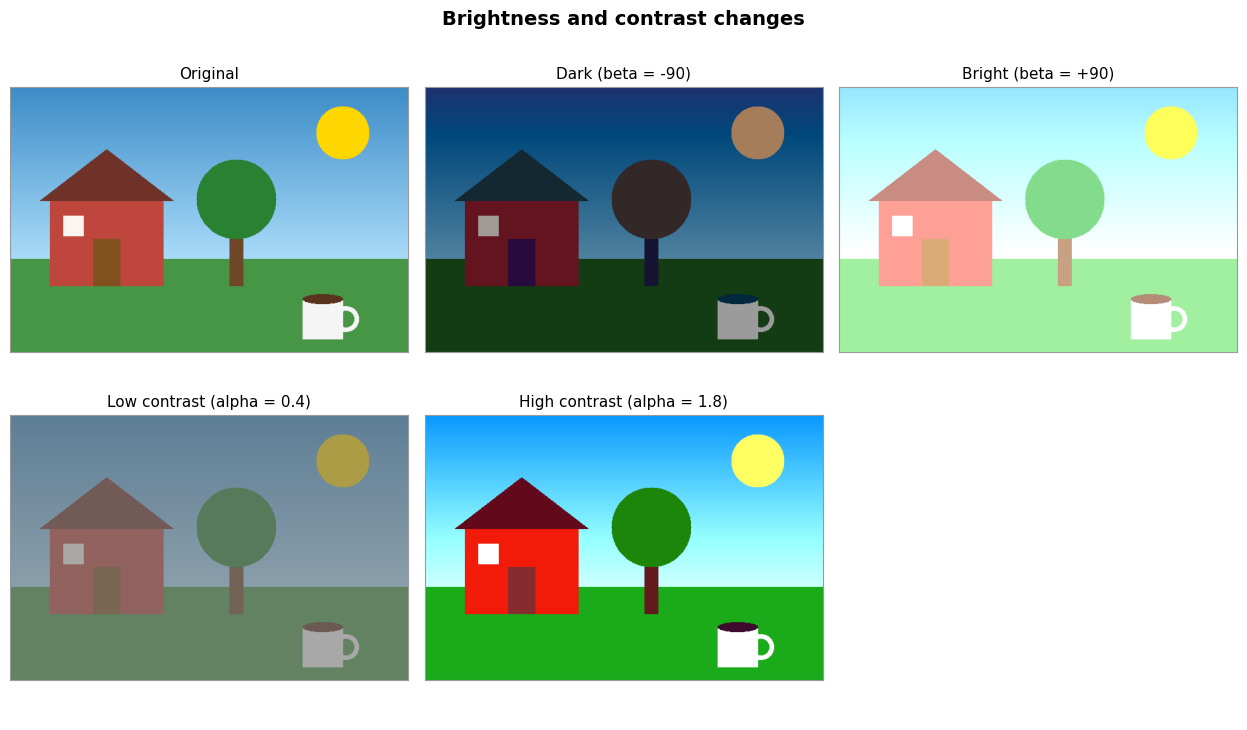

In [ ]:
dark   = cv2.convertScaleAbs(scene, alpha=1.0, beta=-90)   # subtract 90 from every pixel
bright = cv2.convertScaleAbs(scene, alpha=1.0, beta=90)    # add 90 to every pixel
low    = cv2.convertScaleAbs(scene, alpha=0.4, beta=70)    # squeeze values together
high   = cv2.convertScaleAbs(scene, alpha=1.8, beta=-100)  # stretch values apart

show([scene, dark, bright, low, high],
     ["Original", "Dark (beta = -90)", "Bright (beta = +90)", "Low contrast (alpha = 0.4)", "High contrast (alpha = 1.8)"],
     cols=3, size=4.2, suptitle="Brightness and contrast changes")

## What is a histogram?
A **histogram** is a summary of how dark or bright the pixels in an image are. Think of it as sorting all pixels into buckets from black (0) to white (255) and counting how many land in each bucket.
- Bars on the **left** = many dark pixels
- Bars on the **right** = many bright pixels
- A narrow hill = low contrast. A wide spread = high contrast

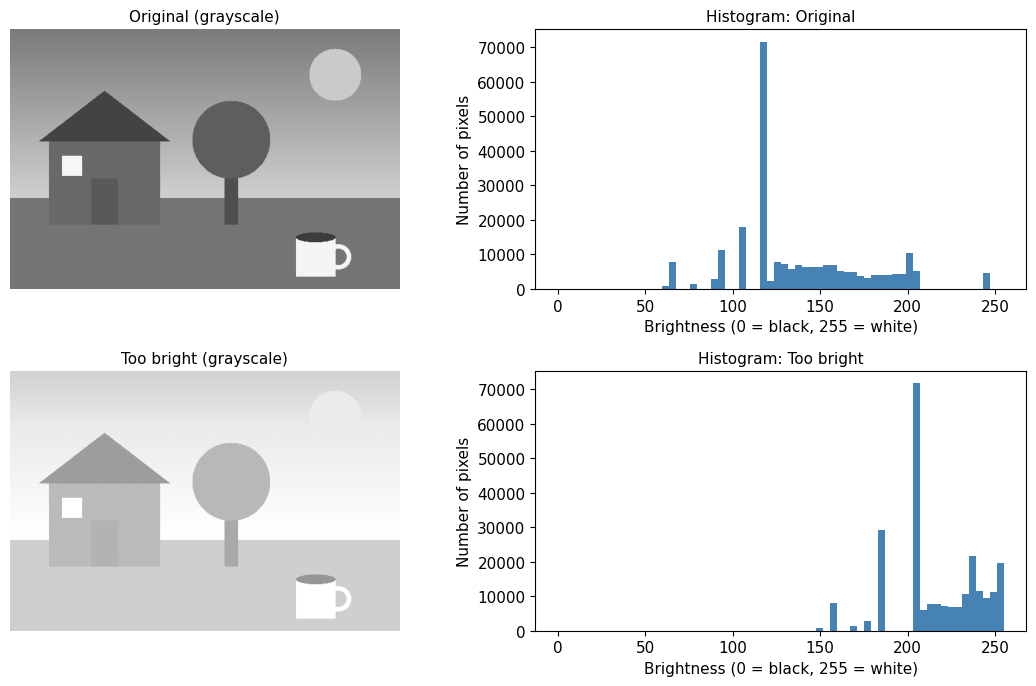

In [ ]:
bright_gray = cv2.cvtColor(bright, cv2.COLOR_BGR2GRAY)

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for row, (img, name) in enumerate([(gray, "Original"), (bright_gray, "Too bright")]):
    ax[row, 0].imshow(img, cmap="gray", vmin=0, vmax=255); ax[row, 0].axis("off")
    ax[row, 0].set_title(name + " (grayscale)")
    ax[row, 1].hist(img.ravel(), bins=64, range=(0, 255), color="steelblue")
    ax[row, 1].set_title("Histogram: " + name)
    ax[row, 1].set_xlabel("Brightness (0 = black, 255 = white)"); ax[row, 1].set_ylabel("Number of pixels")
plt.tight_layout(); plt.show()

**What to notice:** in the bright image the hill moves right and a tall spike appears at 255. Those pixels are **clipped**: they are pure white and the detail inside them is gone for good.

> **Discuss**
> 1. Which image is easiest to see? Why?
> 2. What happens when an image becomes too bright?
> 3. Does increasing contrast *always* improve an image? (Look at the high-contrast picture: what happened to the sky and the grass?)


# Part 3: Blurring, filtering and noise reduction

**Noise** = unwanted random changes in pixel values (think of the "grain" in a photo taken in the dark)

A **blur filter** replaces each pixel with a value calculated from its neighbors:
- **Average blur**: smooths neighboring pixels equally
- **Gaussian blur**: gives nearby pixels more weight than faraway ones
- **Median blur**: replaces the pixel with the *middle value* of its neighborhood. Great for "salt-and-pepper" noise

We zoom in on the house so the noise is easier to see

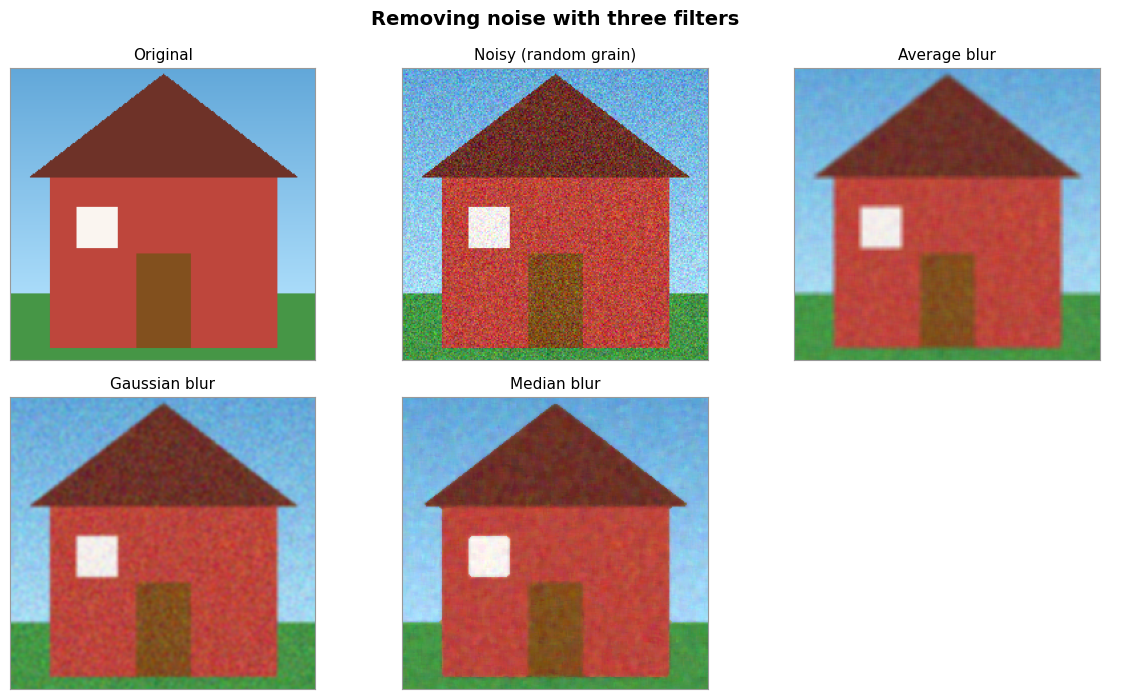

In [ ]:
noise = np.random.normal(0, 25, scene.shape)                   # random grain
noisy = np.clip(scene + noise, 0, 255).astype(np.uint8)

avg   = cv2.blur(noisy, (5, 5))
gauss = cv2.GaussianBlur(noisy, (5, 5), 0)
med   = cv2.medianBlur(noisy, 5)

zoom = lambda im: im[90:310, 30:260]                           # crop around the house
show([zoom(scene), zoom(noisy), zoom(avg), zoom(gauss), zoom(med)],
     ["Original", "Noisy (random grain)", "Average blur", "Gaussian blur", "Median blur"],
     cols=3, size=4, suptitle="Removing noise with three filters")

**Captions**
- **Noisy:** grainy dots appear everywhere
- **Average:** noise is reduced, but edges look soft
- **Gaussian:** similar to average but looks a little more natural
- **Median:** keeps edges sharper than the other two

## Salt-and-pepper noise
This is a different kind of noise: a few pixels become pure **black or white** like salt and pepper sprinkled on the image

> 🤔 **Predict first:** Which filter will work better here **Gaussian** or **Median**?

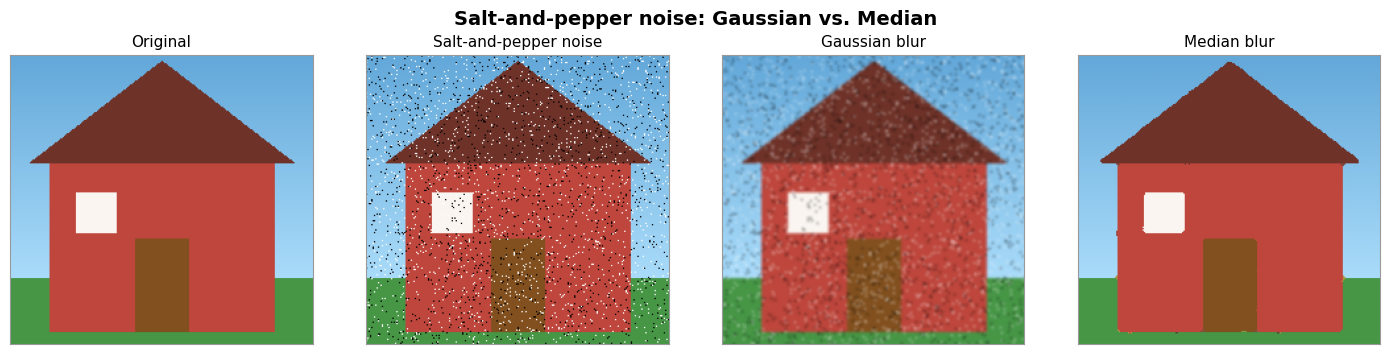

In [ ]:
sp = scene.copy()
r = np.random.rand(*scene.shape[:2])
sp[r < 0.03] = 0              # 3% black "pepper" pixels
sp[r > 0.97] = 255            # 3% white "salt" pixels

sp_gauss = cv2.GaussianBlur(sp, (5, 5), 0)
sp_med   = cv2.medianBlur(sp, 5)

show([zoom(scene), zoom(sp), zoom(sp_gauss), zoom(sp_med)],
     ["Original", "Salt-and-pepper noise", "Gaussian blur", "Median blur"],
     cols=4, size=3.6, suptitle="Salt-and-pepper noise: Gaussian vs. Median")

**What to notice:** Gaussian blur *smears* the black and white dots into gray blotches. Median blur simply ignores them, because a few extreme values are never the middle value.

## The limitation: blur also removes real detail
Filters cannot tell the difference between noise and small useful details.

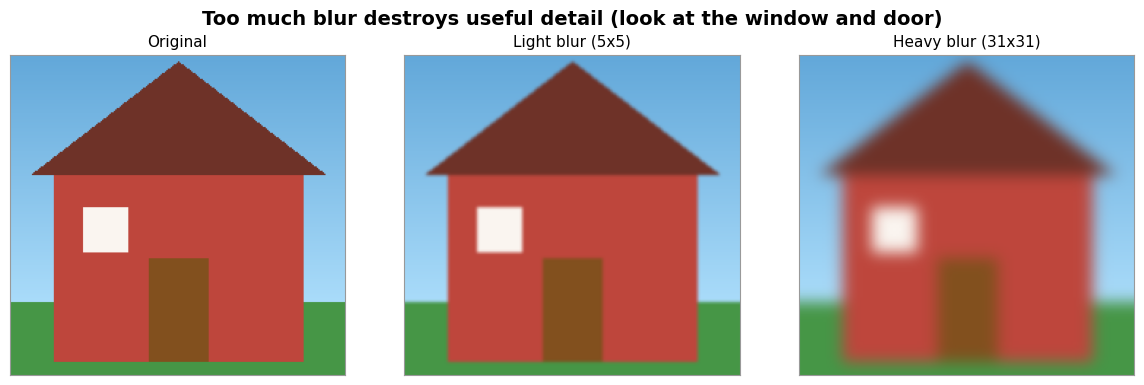

In [ ]:
light = cv2.GaussianBlur(scene, (5, 5), 0)
heavy = cv2.GaussianBlur(scene, (31, 31), 0)
show([zoom(scene), zoom(light), zoom(heavy)],
     ["Original", "Light blur (5x5)", "Heavy blur (31x31)"],
     cols=3, size=4, suptitle="Too much blur destroys useful detail (look at the window and door)")

# Part 4: Thresholding and binary images  

**Thresholding** turns a gray image into a **binary image** (only black and white):
- pixel **above** the threshold → set to **255** (white)
- pixel **below** it → set to **0** (black)

The threshold is just a cut-off number. Changing it changes what counts as "foreground"

> 🤔 **Predict first:** With a *low* threshold will the result be mostly white or mostly black?

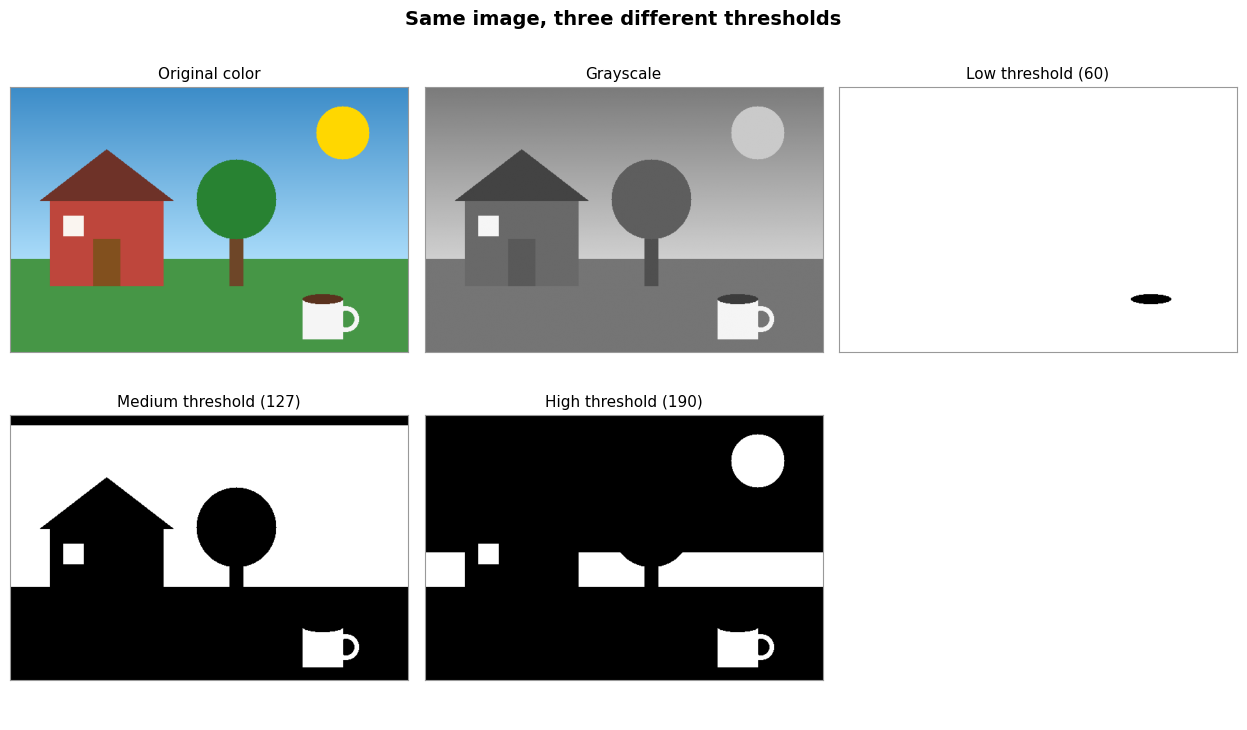

In [ ]:
results = []
for t in (60, 127, 190):
    _, binary = cv2.threshold(gray, t, 255, cv2.THRESH_BINARY)
    results.append(binary)

show([scene, gray] + results,
     ["Original color", "Grayscale", "Low threshold (60)", "Medium threshold (127)", "High threshold (190)"],
     cols=3, size=4.2, suptitle="Same image, three different thresholds")

**What to notice:** a low threshold keeps almost everything white; a high threshold keeps only the brightest parts (the sun, the cup, and the pale sky near the horizon). There is no "perfect" number for every image.

## Where is thresholding useful?
A scanned document is a great example: dark text on a light page.

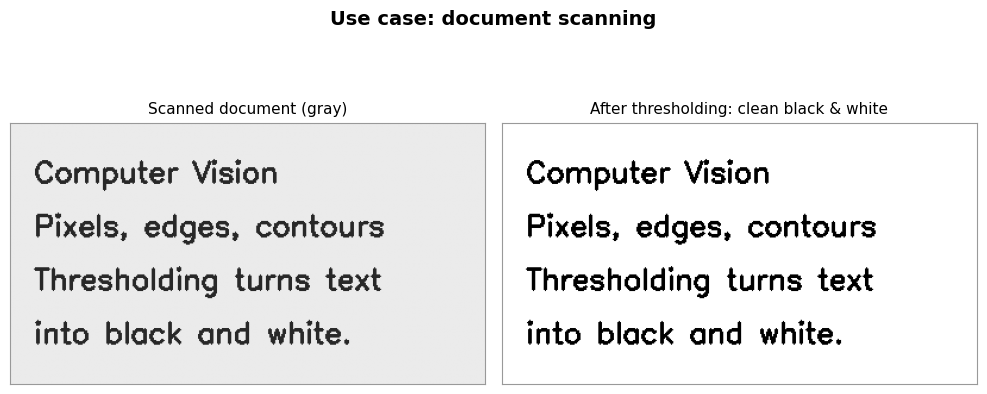

In [ ]:
def make_document(shadow=False):
    doc = np.full((220, 400), 235, np.uint8)
    lines = ["Computer Vision", "Pixels, edges, contours", "Thresholding turns text", "into black and white."]
    for i, text in enumerate(lines):
        cv2.putText(doc, text, (20, 50 + i * 45), cv2.FONT_HERSHEY_SIMPLEX, 0.8, 40, 2)
    if shadow:                                          # light fades from left to right
        doc = (doc * np.linspace(1.0, 0.35, 400)[None, :]).astype(np.uint8)
    return doc

doc = make_document()
_, doc_bin = cv2.threshold(doc, 127, 255, cv2.THRESH_BINARY)
show([doc, doc_bin], ["Scanned document (gray)", "After thresholding: clean black & white"],
     cols=2, size=5, suptitle="Use case: document scanning")

Other typical uses: **separating an object from a simple background** (a dark part on a white conveyor belt) and **basic industrial inspection** (is the bottle cap present or not?).

## ⚠️ When thresholding does NOT work
Thresholding only looks at **brightness** never at color or meaning. If the object and background have the **same brightness** they become impossible to separate

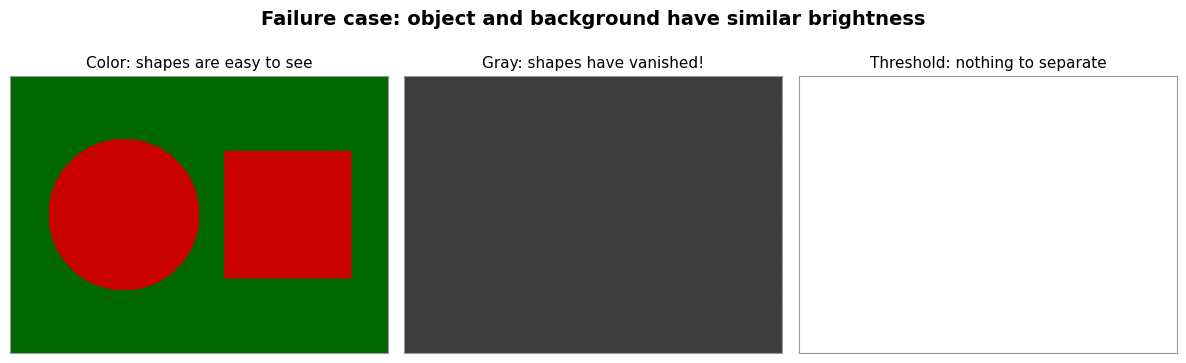

In [ ]:
# A red shape on a green background. The colors differ, but the GRAY brightness is almost identical.
fail = np.zeros((220, 300, 3), np.uint8)
fail[:] = (0, 102, 0)
cv2.circle(fail, (90, 110), 60, (0, 0, 200), -1)
cv2.rectangle(fail, (170, 60), (270, 160), (0, 0, 200), -1)
fail_gray = cv2.cvtColor(fail, cv2.COLOR_BGR2GRAY)
_, fail_bin = cv2.threshold(fail_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show([fail, fail_gray, fail_bin],
     ["Color: shapes are easy to see", "Gray: shapes have vanished!", "Threshold: nothing to separate"],
     cols=3, size=4, suptitle="Failure case: object and background have similar brightness")

### ⏭️ OPTIONAL: Otsu's method and uneven lighting
**Otsu's method** picks the threshold *automatically* by looking at the histogram. It is great when lighting is even. When lighting is uneven (a shadow) one global number fails and **adaptive thresholding** (a different threshold for each small neighborhood) helps

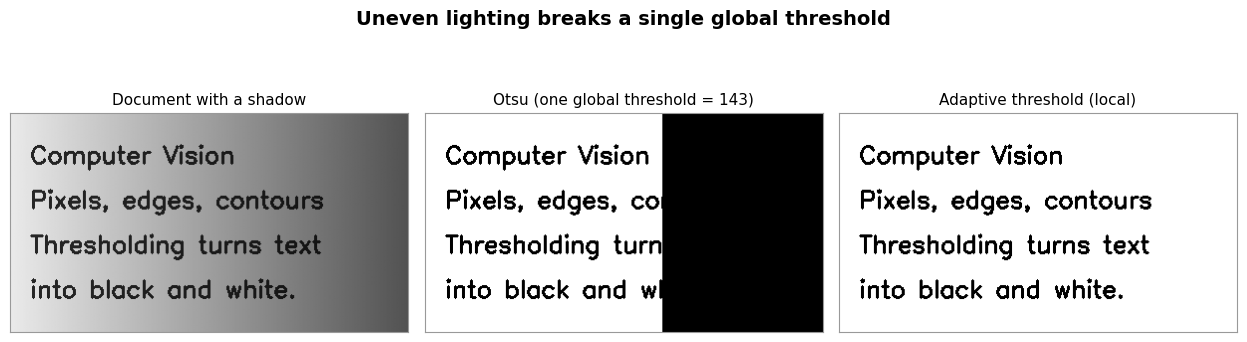

In [ ]:
shadowed = make_document(shadow=True)
t, otsu = cv2.threshold(shadowed, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
adaptive = cv2.adaptiveThreshold(shadowed, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 15)

show([shadowed, otsu, adaptive],
     ["Document with a shadow", f"Otsu (one global threshold = {int(t)})", "Adaptive threshold (local)"],
     cols=3, size=4.2, suptitle="Uneven lighting breaks a single global threshold")

# Part 5: Edge detection, Sobel and Canny  

An **edge** is a place where brightness changes sharply for example where the dark roof meets the light sky

- **Sobel** measures how fast brightness changes in one direction: **x** (left→right) finds *vertical* edges, **y** (top→bottom) finds *horizontal* edges

- **Canny** is a multi-step recipe (smooth → find gradients → thin the lines → keep strong edges) that produces a clean map of edges

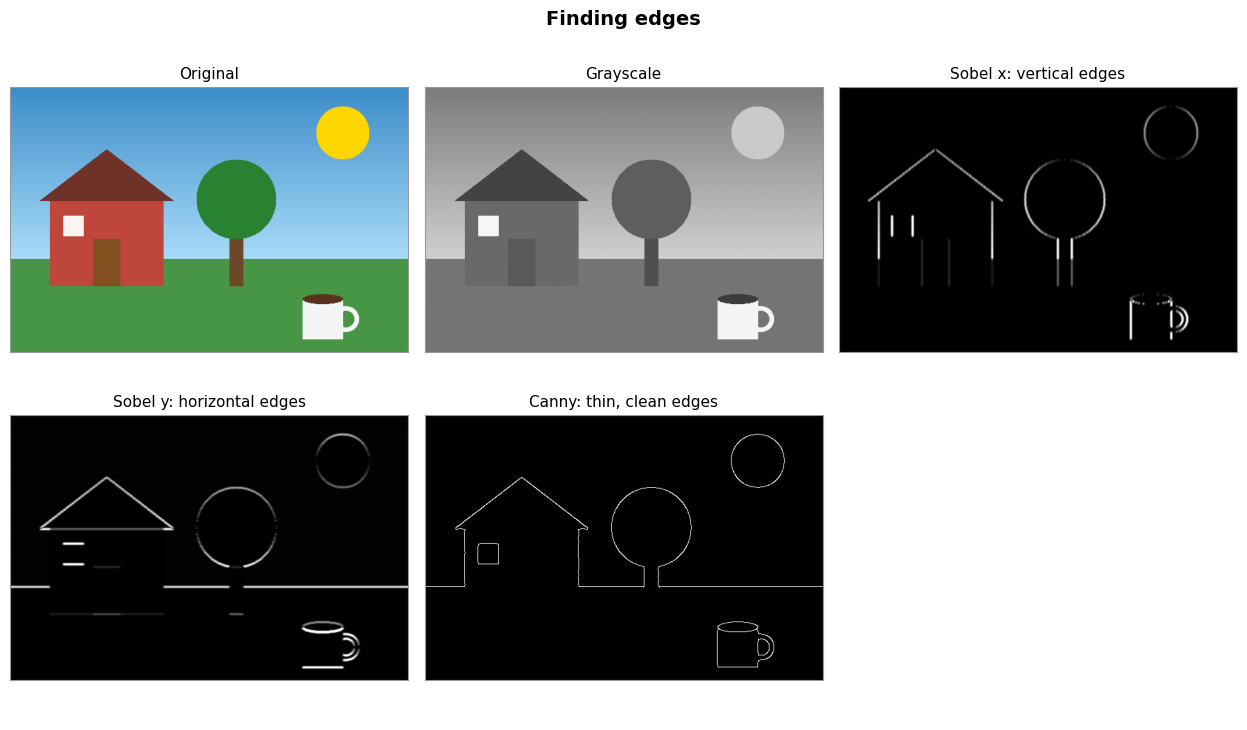

In [ ]:
blur = cv2.GaussianBlur(gray, (5, 5), 0)                        # smooth first so noise is not mistaken for edges
sobel_x = cv2.convertScaleAbs(cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3))
sobel_y = cv2.convertScaleAbs(cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=3))
canny   = cv2.Canny(blur, 100, 200)

show([scene, gray, sobel_x, sobel_y, canny],
     ["Original", "Grayscale", "Sobel x: vertical edges", "Sobel y: horizontal edges", "Canny: thin, clean edges"],
     cols=3, size=4.2, suptitle="Finding edges")

**What to notice**
- Sobel **x** lights up the *sides* of the house, trunk and cup; Sobel **y** lights up the roof line and the horizon.
- Canny gives thin one-pixel lines and ignores weak gradients such as the smooth sky.

## Canny thresholds
Canny has two numbers, a **low** and a **high** threshold. Edges stronger than *high* are kept; weaker than *low* are dropped.

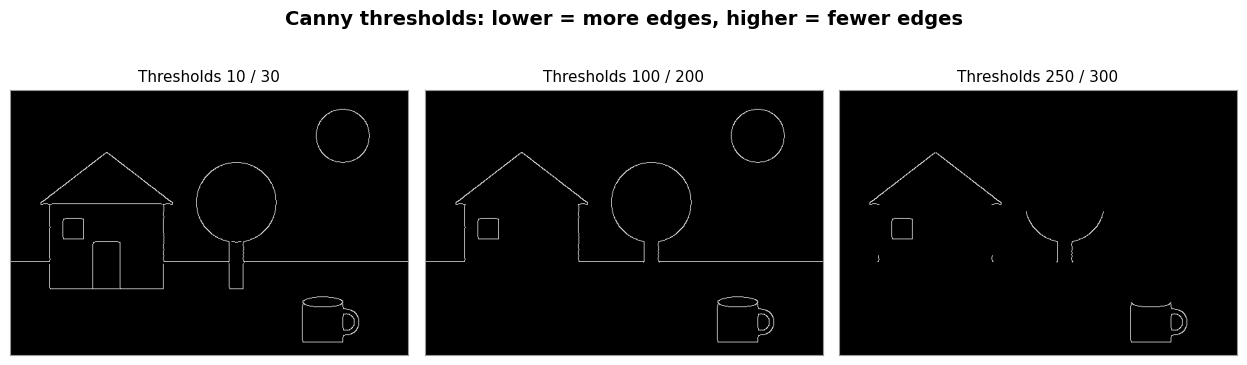

In [ ]:
pairs = [(10, 30), (100, 200), (250, 300)]
edges = [cv2.Canny(blur, lo, hi) for lo, hi in pairs]
show(edges, [f"Thresholds {lo} / {hi}" for lo, hi in pairs],
     cols=3, size=4.2, suptitle="Canny thresholds: lower = more edges, higher = fewer edges")

**What to notice:** the low pair (10 / 30) even finds the faint door; the high pair (250 / 300) starts to lose real edges (parts of the roof and tree are gone)

> 💬 **Discuss:** *If the computer detects the edges of a cup, does that mean it knows the object is a cup?*

**No.** Edge detection finds **boundaries**, not **meaning**. The computer only knows "brightness changes here". Deciding that the shape is a cup needs more: that is where learned models (Part 8) come in

# Part 6: Morphological operations  

Morphology changes the *shape* of white regions in a **binary image**. A small square called a **structuring element** (kernel) slides across the image like a stamp

| Operation | What it does |
|---|---|
| **Erosion** | white regions get **smaller** (thin parts disappear) |
| **Dilation** | white regions get **larger** (small holes fill in) |
| **Opening** = erosion then dilation | removes **small white specks** |
| **Closing** = dilation then erosion | fills **small gaps** inside white regions |

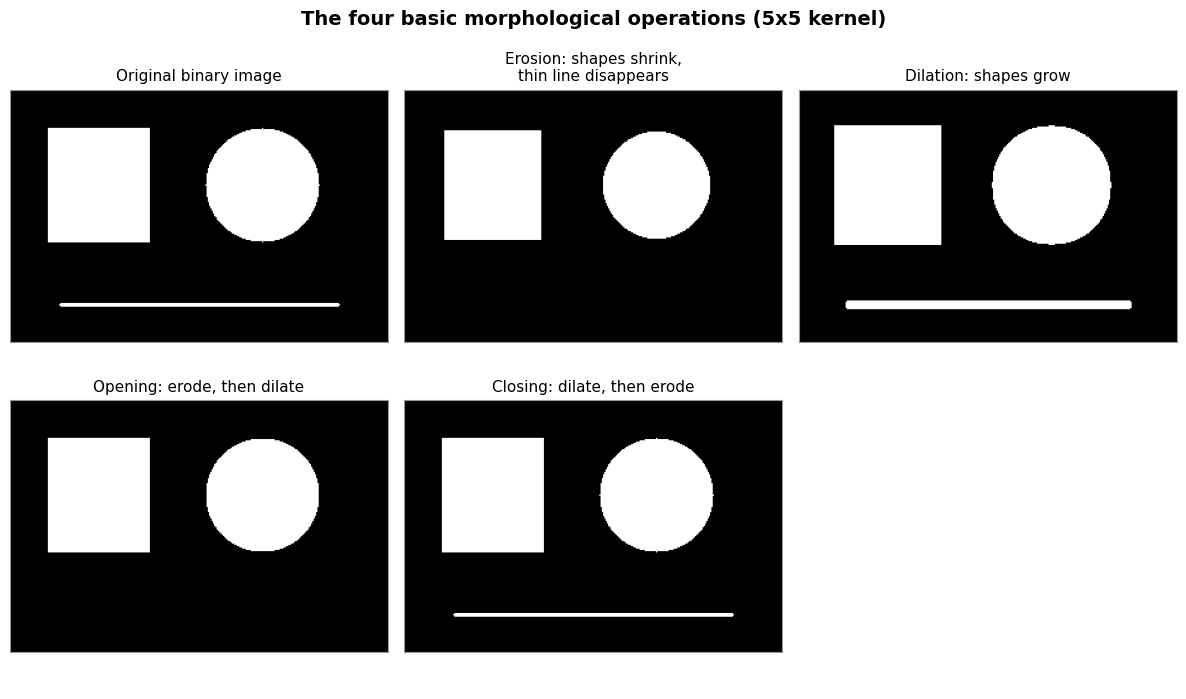

In [ ]:
shapes = np.zeros((200, 300), np.uint8)
cv2.rectangle(shapes, (30, 30), (110, 120), 255, -1)           # rectangle
cv2.circle(shapes, (200, 75), 45, 255, -1)                     # circle
cv2.line(shapes, (40, 170), (260, 170), 255, 2)                # a thin line (2 pixels)

kernel = np.ones((5, 5), np.uint8)                             # the 5x5 "stamp"
eroded  = cv2.erode(shapes, kernel)
dilated = cv2.dilate(shapes, kernel)
opened  = cv2.morphologyEx(shapes, cv2.MORPH_OPEN, kernel)
closed  = cv2.morphologyEx(shapes, cv2.MORPH_CLOSE, kernel)

show([shapes, eroded, dilated, opened, closed],
     ["Original binary image", "Erosion: shapes shrink,\nthin line disappears", "Dilation: shapes grow",
      "Opening: erode, then dilate", "Closing: dilate, then erode"],
     cols=3, size=4, suptitle="The four basic morphological operations (5x5 kernel)")

**What to notice:** erosion makes the shapes smaller and erases the thin line; dilation grows everything; opening also removed the thin line (it was too thin to survive), while closing kept it. Operations can destroy real structures if the kernel is too big.

## A more realistic example: cleaning up a messy mask
Here a white rectangle has **random white dots** around it plus **black holes and a thin crack** inside

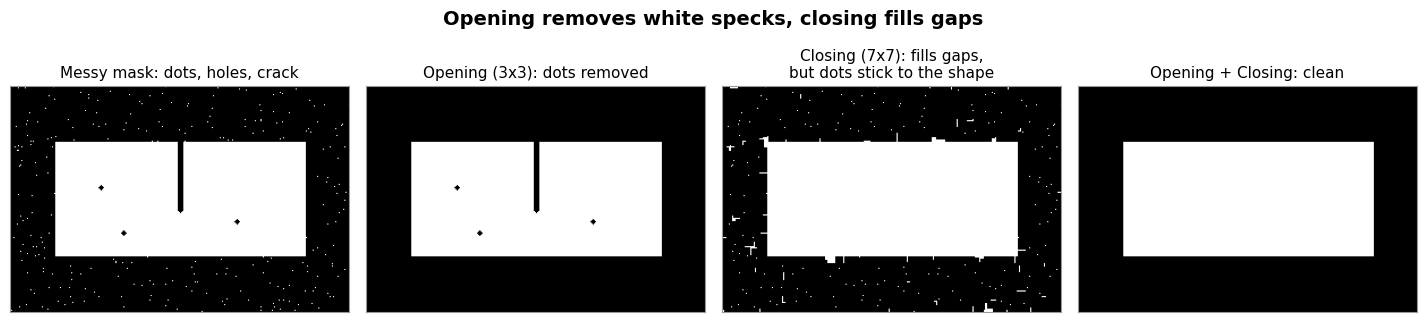

In [ ]:
messy = np.zeros((200, 300), np.uint8)
messy[np.random.rand(200, 300) > 0.992] = 255                  # tiny white dots (noise)
cv2.rectangle(messy, (40, 50), (260, 150), 255, -1)            # the real object
cv2.line(messy, (150, 50), (150, 110), 0, 3)                   # a thin crack
for px, py in [(80, 90), (200, 120), (100, 130)]:
    cv2.circle(messy, (px, py), 2, 0, -1)                      # small black holes

opened  = cv2.morphologyEx(messy, cv2.MORPH_OPEN,  np.ones((3, 3), np.uint8))
closed  = cv2.morphologyEx(messy, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
cleaned = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))

show([messy, opened, closed, cleaned],
     ["Messy mask: dots, holes, crack", "Opening (3x3): dots removed", "Closing (7x7): fills gaps,\nbut dots stick to the shape", "Opening + Closing: clean"],
     cols=4, size=3.6, suptitle="Opening removes white specks, closing fills gaps")

### ⏭️ OPTIONAL: Too much morphology
Applying an operation too strongly merges separate objects or erases real structures.

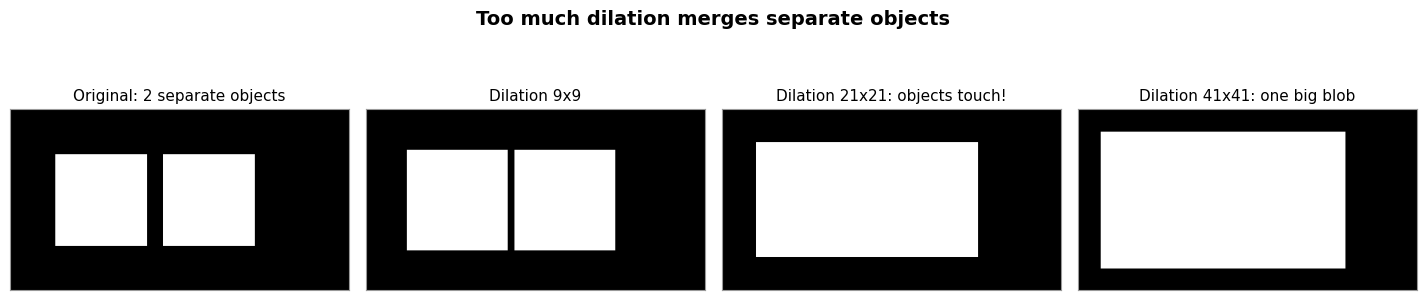

In [ ]:
two = np.zeros((160, 300), np.uint8)
cv2.rectangle(two, (40, 40), (120, 120), 255, -1)
cv2.rectangle(two, (135, 40), (215, 120), 255, -1)             # only 15 pixels apart

show([two] + [cv2.dilate(two, np.ones((k, k), np.uint8)) for k in (9, 21, 41)],
     ["Original: 2 separate objects", "Dilation 9x9", "Dilation 21x21: objects touch!", "Dilation 41x41: one big blob"],
     cols=4, size=3.6, suptitle="Too much dilation merges separate objects")

# Part 7: Contours and traditional computer vision  

A **contour** is the outline of a white region in a binary image

A **bounding box** is the smallest upright rectangle that contains it which gives an *approximate location*

A classic pipeline: **image → gray → threshold → find contours → apply a rule** (e.g. "ignore anything smaller than 500 pixels")

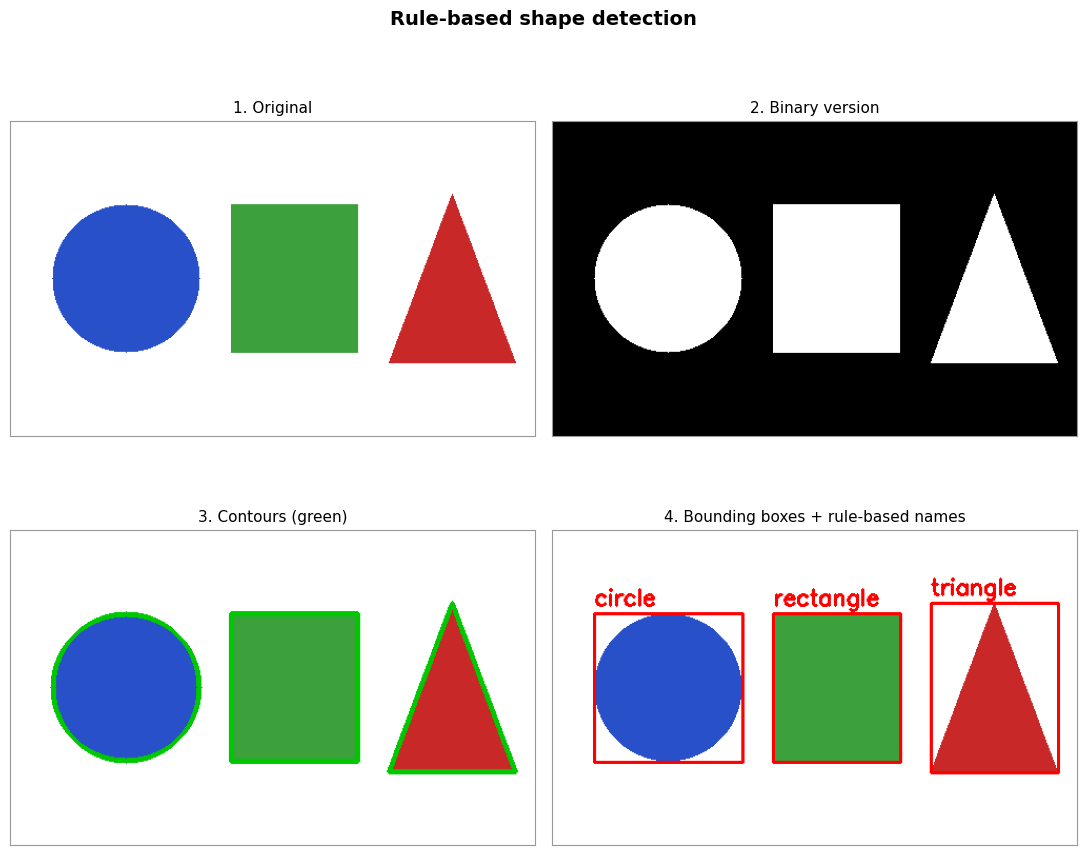

In [ ]:
def make_shapes():
    img = np.full((300, 500, 3), 255, np.uint8)
    cv2.circle(img, (110, 150), 70, (200, 80, 40), -1)
    cv2.rectangle(img, (210, 80), (330, 220), (60, 160, 60), -1)
    cv2.fillPoly(img, [np.array([[420, 70], [360, 230], [480, 230]], np.int32)], (40, 40, 200))
    return img

def find_shapes(img, thresh=200, min_area=500):
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, binary = cv2.threshold(g, thresh, 255, cv2.THRESH_BINARY_INV)      # dark objects -> white
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    outlined, boxed = img.copy(), img.copy()
    for c in contours:
        if cv2.contourArea(c) < min_area:                                 # RULE 1: ignore tiny blobs
            continue
        corners = len(cv2.approxPolyDP(c, 0.04 * cv2.arcLength(c, True), True))
        name = {3: "triangle", 4: "rectangle"}.get(corners, "circle")     # RULE 2: count the corners
        x, y, w, h = cv2.boundingRect(c)
        cv2.drawContours(outlined, [c], -1, (0, 200, 0), 3)
        cv2.rectangle(boxed, (x, y), (x + w, y + h), (0, 0, 255), 2)
        cv2.putText(boxed, name, (x, max(y - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
    return binary, outlined, boxed

shapes_img = make_shapes()
binary, outlined, boxed = find_shapes(shapes_img)
show([shapes_img, binary, outlined, boxed],
     ["1. Original", "2. Binary version", "3. Contours (green)", "4. Bounding boxes + rule-based names"],
     cols=2, size=5.5, suptitle="Rule-based shape detection")

**Why it works here:** the shapes are simple, high contrast, separate, and sit on a clean background. Our hand-written rules ("big enough", "count the corners") are enough.

## ⚠️ A failure case
Now the same code on a harder image: **overlapping shapes**, a **textured background** and **noise**. We changed nothing in the code.

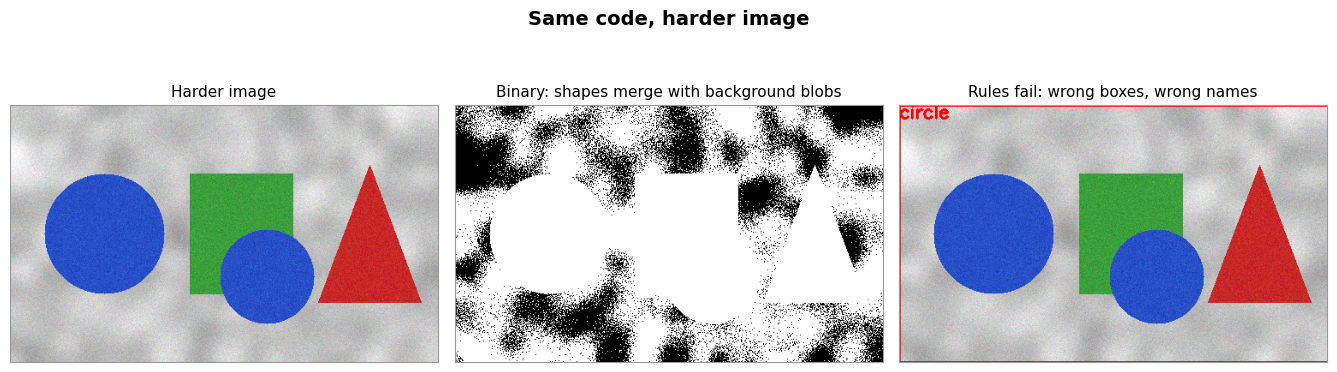

In [ ]:
messy_img = make_shapes()
cv2.circle(messy_img, (300, 200), 55, (200, 80, 40), -1)               # a new circle overlapping the rectangle

clouds = cv2.GaussianBlur(np.random.rand(300, 500).astype(np.float32), (0, 0), 12)
clouds = (clouds - clouds.min()) / (clouds.max() - clouds.min())        # smooth random pattern 0..1
background = (160 + 95 * clouds).astype(np.uint8)
white = np.all(messy_img == 255, axis=2)
messy_img[white] = np.dstack([background] * 3)[white]                   # replace plain white with cloudy background
messy_img = np.clip(messy_img + np.random.normal(0, 12, messy_img.shape), 0, 255).astype(np.uint8)

m_binary, m_outlined, m_boxed = find_shapes(messy_img)
show([messy_img, m_binary, m_boxed],
     ["Harder image", "Binary: shapes merge with background blobs", "Rules fail: wrong boxes, wrong names"],
     cols=3, size=4.5, suptitle="Same code, harder image")

**What went wrong:** the overlapping shapes became one object, the background was mistaken for objects, and the "corner counting" rule gave wrong names.

> 💬 **Discuss:** *Would the same rules work reliably for objects in a crowded street photograph?*
> Think about: overlapping people, shadows, different lighting, objects of every shape and size. You would need thousands of special rules.

# Part 8: Traditional computer vision vs. deep learning  
*(Conceptual section: no training happens here)*

- **Traditional computer vision:** a developer **designs the steps and rules** by hand
- **Deep learning:** a **CNN** (Convolutional Neural Network) **learns useful patterns from many training examples**

Neither approach is guaranteed to work perfectly in every situation

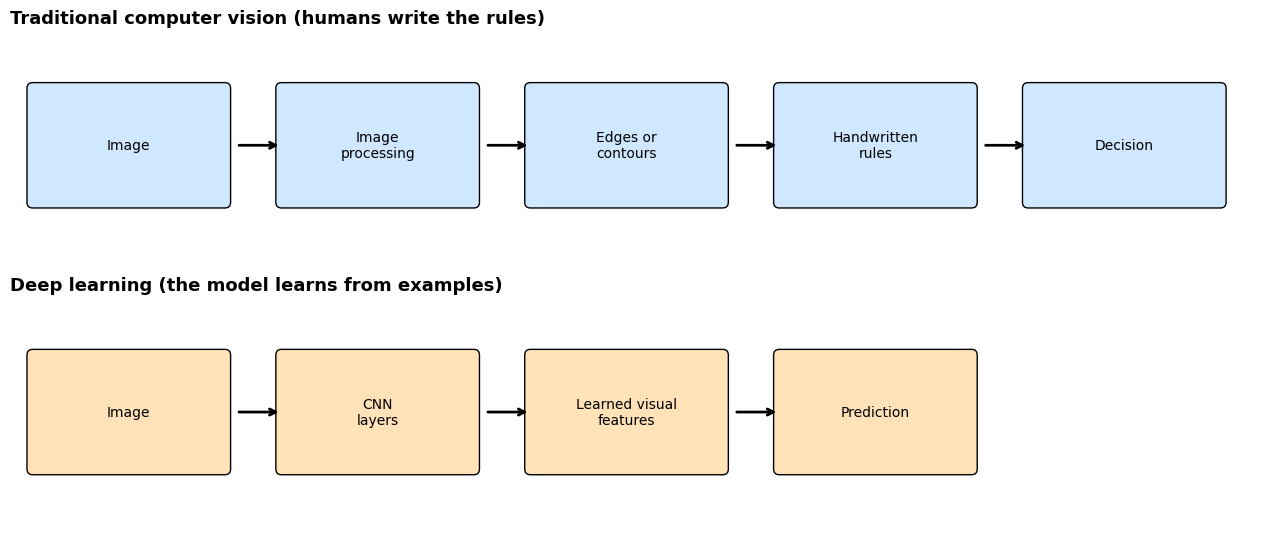

In [ ]:
def pipeline(ax, steps, color, title):
    ax.set_xlim(-0.2, 11); ax.set_ylim(0, 2); ax.axis("off")
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold")
    for i, step in enumerate(steps):
        x = i * 2.2
        ax.add_patch(plt.matplotlib.patches.FancyBboxPatch((x, 0.5), 1.7, 1.0, boxstyle="round,pad=0.05", fc=color, ec="black"))
        ax.text(x + 0.85, 1.0, step, ha="center", va="center", fontsize=10)
        if i < len(steps) - 1:
            ax.annotate("", xy=(x + 2.2, 1.0), xytext=(x + 1.8, 1.0), arrowprops=dict(arrowstyle="->", lw=2))

fig, ax = plt.subplots(2, 1, figsize=(13, 5.5))
pipeline(ax[0], ["Image", "Image\nprocessing", "Edges or\ncontours", "Handwritten\nrules", "Decision"], "#cfe8ff", "Traditional computer vision (humans write the rules)")
pipeline(ax[1], ["Image", "CNN\nlayers", "Learned visual\nfeatures", "Prediction"], "#ffe2b8", "Deep learning (the model learns from examples)")
plt.tight_layout(); plt.show()

## What does a CNN learn? (conceptual picture)
A CNN stacks many layers. Early layers detect simple things later layers combine them into more complex ones

> ⚠️ **This is a conceptual illustration drawn with code. It is *not* the real output of a trained model**

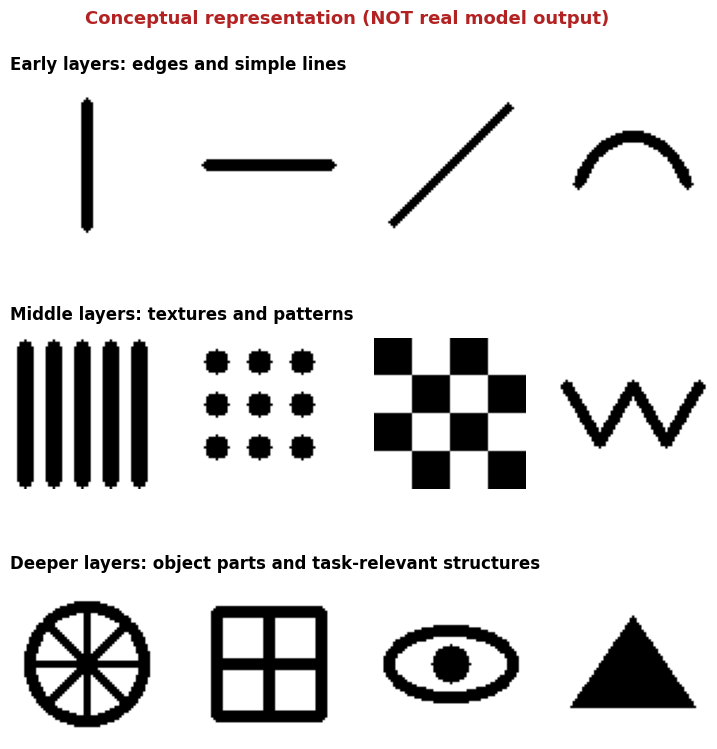

In [ ]:
def tile(draw):
    t = np.full((64, 64), 255, np.uint8); draw(t); return t

early = [tile(lambda t: cv2.line(t, (32, 6), (32, 58), 0, 4)),                  # vertical line
         tile(lambda t: cv2.line(t, (6, 32), (58, 32), 0, 4)),                  # horizontal line
         tile(lambda t: cv2.line(t, (8, 56), (56, 8), 0, 4)),                   # diagonal line
         tile(lambda t: cv2.ellipse(t, (32, 50), (24, 30), 0, 200, 340, 0, 4))] # curve
def stripes(t):
    for i in range(6, 64, 12): cv2.line(t, (i, 4), (i, 60), 0, 5)
def dots(t):
    for i in range(10, 64, 18):
        for j in range(10, 64, 18): cv2.circle(t, (i, j), 5, 0, -1)
def checker(t):
    for i in range(4):
        for j in range(4):
            if (i + j) % 2 == 0: t[i*16:(i+1)*16, j*16:(j+1)*16] = 0
def zigzag(t):
    pts = np.array([[4 + 14*i, 20 + (i % 2) * 24] for i in range(5)], np.int32)
    cv2.polylines(t, [pts], False, 0, 4)
middle = [tile(stripes), tile(dots), tile(checker), tile(zigzag)]
def wheel(t):
    cv2.circle(t, (32, 32), 24, 0, 4)
    for a in range(0, 180, 45):
        d = (int(24*np.cos(np.radians(a))), int(24*np.sin(np.radians(a))))
        cv2.line(t, (32 - d[0], 32 - d[1]), (32 + d[0], 32 + d[1]), 0, 2)
def window(t):
    cv2.rectangle(t, (10, 10), (54, 54), 0, 4); cv2.line(t, (32, 10), (32, 54), 0, 3); cv2.line(t, (10, 32), (54, 32), 0, 3)
def eye(t):
    cv2.ellipse(t, (32, 32), (26, 14), 0, 0, 360, 0, 3); cv2.circle(t, (32, 32), 8, 0, -1)
def roof(t):
    cv2.fillPoly(t, [np.array([[6, 50], [32, 12], [58, 50]], np.int32)], 0)
parts = [tile(wheel), tile(window), tile(eye), tile(roof)]

rows = [(early,  "Early layers: edges and simple lines"),
        (middle, "Middle layers: textures and patterns"),
        (parts,  "Deeper layers: object parts and task-relevant structures")]
fig, ax = plt.subplots(3, 4, figsize=(9, 8.5))
for r, (tiles, label) in enumerate(rows):
    for c, t in enumerate(tiles):
        ax[r, c].imshow(t, cmap="gray", vmin=0, vmax=255); ax[r, c].axis("off")
    ax[r, 0].annotate(label, xy=(0, 1.12), xycoords="axes fraction", fontsize=12, fontweight="bold")
fig.suptitle("Conceptual representation (NOT real model output)", color="firebrick", fontsize=13, fontweight="bold")
plt.subplots_adjust(hspace=0.45, top=0.9)
plt.show()

## Three common vision tasks (same image)
- **Classification:** *one label* for the whole image
- **Object detection:** *labels + bounding boxes* around objects
- **Segmentation:** a *colored mask* showing which **pixel** belongs to which region or object

*(In this illustration the boxes and masks come from how we drew the scene. A real deep learning model would **predict** them)*

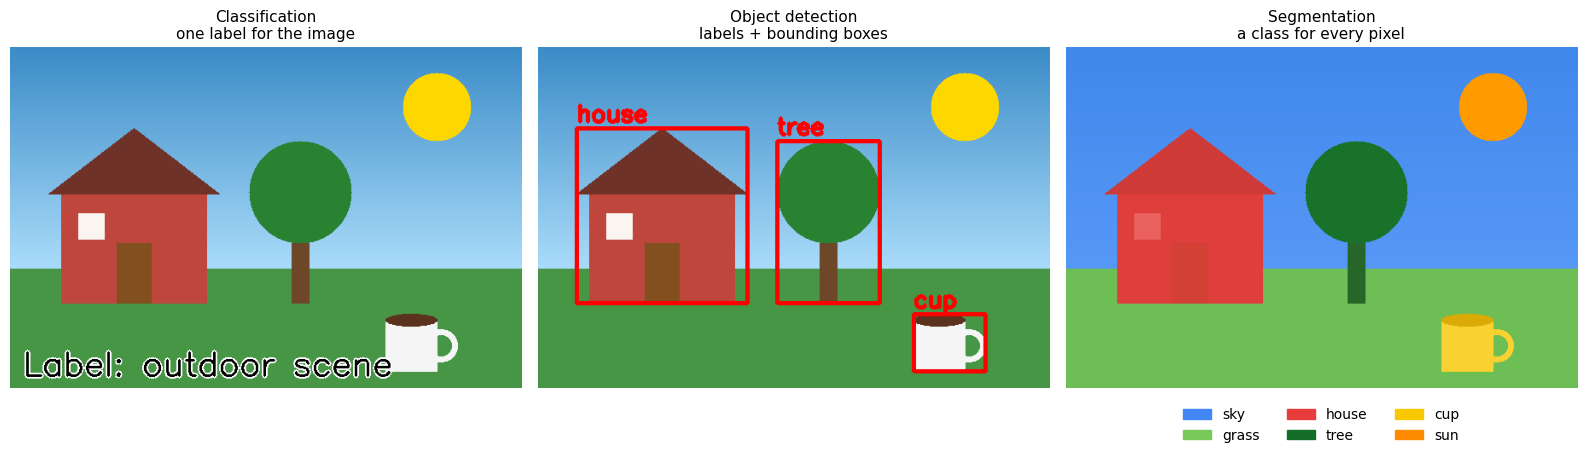

In [ ]:
from matplotlib.patches import Patch

# 1) Classification: one label for the whole image
cls = scene.copy()
cv2.putText(cls, "Label: outdoor scene", (15, 385), cv2.FONT_HERSHEY_SIMPLEX, 1.3, (255, 255, 255), 6)
cv2.putText(cls, "Label: outdoor scene", (15, 385), cv2.FONT_HERSHEY_SIMPLEX, 1.3, (0, 0, 0), 2)

# 2) Detection: a box + name for each object
det = scene.copy()
for name, (x1, y1, x2, y2) in scene_boxes.items():
    cv2.rectangle(det, (x1, y1), (x2, y2), (0, 0, 255), 3)
    cv2.putText(det, name, (x1, y1 - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 3)

# 3) Segmentation: every pixel gets a class color
palette = {0: ("sky", (66, 135, 245)), 1: ("grass", (120, 200, 90)), 2: ("house", (230, 60, 60)),
           3: ("tree", (20, 110, 40)), 4: ("cup", (250, 200, 0)), 5: ("sun", (255, 140, 0))}
mask = np.zeros((*scene_labels.shape, 3), np.uint8)
for k, (_, color) in palette.items():
    mask[scene_labels == k] = color
seg = (0.2 * rgb + 0.8 * mask).astype(np.uint8)          # blend picture and colored mask

fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))
ax[0].imshow(cv2.cvtColor(cls, cv2.COLOR_BGR2RGB)); ax[0].set_title("Classification\none label for the image")
ax[1].imshow(cv2.cvtColor(det, cv2.COLOR_BGR2RGB)); ax[1].set_title("Object detection\nlabels + bounding boxes")
ax[2].imshow(seg);                                   ax[2].set_title("Segmentation\na class for every pixel")
ax[2].legend(handles=[Patch(color=np.array(c) / 255, label=n) for n, c in palette.values()],
             loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=10, frameon=False)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()